# ISyE 6767 Lab 2 — Building the Project 2 dataset from raw ERCOT files

Project 2 trades the DART spread at ERCOT's North Hub:

$$S_{D,h} = P^{DA}_{D,h} - P^{RT}_{D,h}, \qquad y_{D,h} = \mathbb{1}\{S_{D,h} > 0\}.$$

All trades for day $D$ are decided at **9:00 AM on day $D-1$**. Anything you feed a model must have been
known at that moment. In this lab you build the hourly dataset yourself, starting from the files exactly as ERCOT
publishes them, and you learn one test that catches look-ahead in any feature you build later.

| Folder | ERCOT product | What one file is |
|---|---|---|
| `prices/` | NP4-180-ER, NP6-785-ER | one **year** of DA hub prices (hourly) / RT hub prices (15-minute), one sheet per month |
| `load_forecast/` | NP3-561-CD | 7-day load forecast by weather zone |
| `wind_forecast/` | NP4-732-CD | wind: actuals for the past 48 h + STWPF forecast for the next 7 days |
| `solar_forecast/` | NP4-737-CD | solar: same layout, STPPF forecast |
| `forecast_posting_times.csv` | ERCOT Public API | when each forecast file was posted |

Each forecast file is named after delivery day $D$ and is **the last one ERCOT posted before 9:00 on $D-1$**.
Delivery days: 2022-12-01 to 2025-12-31 (December 2022 is only there so that lags exist on 2023-01-01).

This lab is the data step of **Project 2** (`project2.pdf` on Canvas — read its *Decision time* and *Data Preparation and Cleaning*
sections first). What you build here, `ercot_hb_north_hourly.csv` and the `assert_no_lookahead` test, is where Part 1 of the project starts.

Work through the tasks in order. Each task ends with a **check cell**; when it runs without an `AssertionError`, move on.

In [1]:
%matplotlib inline
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
DATA = Path("lab2_data")      # change this if you unzipped somewhere else
HUB = "HB_NORTH"
TZ = "US/Central"             # ERCOT runs on Central Prevailing Time (CST in winter, CDT in summer)

## Task 0 — Look before you code

Open one sheet of each workbook. Reading Excel is slow (the RT workbooks have ~800k rows each), so look at a single sheet first.

1. How is time written in the DA workbook? In the RT workbook?
2. What does `Repeated Hour Flag` mean? Find a day where it is `Y`.
3. How many rows should a normal day have for one hub in each workbook? A day when clocks go forward? Back?

**Answer (Task 0).**
1. DA workbook: `Delivery Date` is text `MM/DD/YYYY` and `Hour Ending` is text `"01:00"`…`"24:00"` (hour ending, Central Prevailing Time). RT workbook: `Delivery Date` (text), `Delivery Hour` as an integer 1–24 and `Delivery Interval` 1–4 (the four 15-minute intervals of that hour).
2. `Repeated Hour Flag = Y` marks the second copy of hour ending 2 on the fall-back day, the 01:00–02:00 hour that happens a second time in standard time (CST). Example: 11/05/2023.
3. For one hub, DA: 24 rows on a normal day, 23 on the spring-forward day, 25 on the fall-back day. RT: 96, 92 and 100 rows (4 intervals per hour).

In [2]:
print(sorted(p.name for p in (DATA / "prices").glob("*.xlsx")))
da_nov = pd.read_excel(DATA / "prices" / "rpt.00013060.0000000000000000.DAMLZHBSPP_2023.xlsx", sheet_name="Nov")
da_nov.head()

['rpt.00013060.0000000000000000.DAMLZHBSPP_2022.xlsx', 'rpt.00013060.0000000000000000.DAMLZHBSPP_2023.xlsx', 'rpt.00013060.0000000000000000.DAMLZHBSPP_2024.xlsx', 'rpt.00013060.0000000000000000.DAMLZHBSPP_2025.xlsx', 'rpt.00013061.0000000000000000.RTMLZHBSPP_2022.xlsx', 'rpt.00013061.0000000000000000.RTMLZHBSPP_2023.xlsx', 'rpt.00013061.0000000000000000.RTMLZHBSPP_2024.xlsx', 'rpt.00013061.0000000000000000.RTMLZHBSPP_2025.xlsx']


/var/folders/tp/b36n1txj6dj9y2sbnk9q26v00000gn/T/ipykernel_44910/3924965259.py:2: Pandas4Warning: The default engine for reading 'xlsx' files will change from 'openpyxl' to 'calamine' in a future version. Pass engine='openpyxl' (or set the 'io.excel.xlsx.reader' option) to keep the current engine and silence this warning.
  da_nov = pd.read_excel(DATA / "prices" / "rpt.00013060.0000000000000000.DAMLZHBSPP_2023.xlsx", sheet_name="Nov")


,Delivery Date,Hour Ending,Repeated Hour Flag,Settlement Point,Settlement Point Price
0,11/01/2023,01:00,N,HB_BUSAVG,23.80
1,11/01/2023,01:00,N,HB_HOUSTON,23.06
2,11/01/2023,01:00,N,HB_HUBAVG,25.67
3,11/01/2023,01:00,N,HB_NORTH,21.78
4,11/01/2023,01:00,N,HB_PAN,17.92


In [3]:
da_nov[(da_nov["Settlement Point"] == HUB) & (da_nov["Delivery Date"] == "11/05/2023")].head(5)

,Delivery Date,Hour Ending,Repeated Hour Flag,Settlement Point,Settlement Point Price
1443,11/05/2023,01:00,N,HB_NORTH,19.92
1458,11/05/2023,02:00,N,HB_NORTH,21.68
1473,11/05/2023,02:00,Y,HB_NORTH,24.98
1488,11/05/2023,03:00,N,HB_NORTH,22.35
1503,11/05/2023,04:00,N,HB_NORTH,23.01


### Why time is the hard part

ERCOT labels an hour by its **hour ending** in local time: HE 1 is 00:00–01:00, HE 24 is 23:00–24:00.

* **Fall back** (first Sunday of November): 01:00–02:00 happens twice. ERCOT publishes HE 2 twice;
  the second copy has `Repeated Hour Flag = Y` (prices) or `DSTFlag = Y` (forecasts). That day has 25 hours.
* **Spring forward** (second Sunday of March): 02:00–03:00 never happens. That day has 23 hours.

If you key your data on "date + hour" you will merge the wrong rows on those days. We give every hour an
unambiguous key instead: the **start of the hour in UTC**. Hour ending $h$ starts at local time $h-1$;
the repeated copy is standard time, the first copy daylight time.

In [4]:
def hour_start_utc(delivery_date, hour_ending, repeated):
    # Local start = date + (HE - 1) hours. `ambiguous` tells pandas which copy of the repeated hour
    # we mean (True = daylight time = first copy). A label that cannot exist becomes NaT.
    start = pd.to_datetime(delivery_date) + pd.to_timedelta(np.asarray(hour_ending) - 1, unit="h")
    return (pd.DatetimeIndex(start)
            .tz_localize(TZ, ambiguous=~np.asarray(repeated, dtype=bool), nonexistent="NaT")
            .tz_convert("UTC"))


hour_start_utc(["2023-11-05"] * 3, [2, 2, 3], [False, True, False])

DatetimeIndex(['2023-11-05 06:00:00+00:00', '2023-11-05 07:00:00+00:00', '2023-11-05 08:00:00+00:00'], dtype='datetime64[us, UTC]', freq=None)

## Task 1 — Day-ahead prices

Write `read_workbooks(folder, pattern)` that reads **every sheet** of every matching workbook and stacks them
(`pd.read_excel(f, sheet_name=None)` returns a dict of DataFrames), and `load_dam(folder)` that keeps `HB_NORTH` and returns

`delivery_date, hour_ending (int), repeated (bool), da_price, interval_start_utc`.

*Hint:* `"Hour Ending"` looks like `"01:00"`.

In [5]:
def read_workbooks(folder, pattern):
    # So, pd.read_excel(sheet_name=None) gives {month: DataFrame}; let's stack every sheet of every workbook.
    stacked_sheets = []
    for each_workbook in sorted(Path(folder).glob(pattern)):
        month_sheets = pd.read_excel(each_workbook, sheet_name=None, engine="calamine")
        stacked_sheets.extend(month_sheets.values())
    return pd.concat(stacked_sheets, ignore_index=True)


def load_dam(folder):
    raw = read_workbooks(folder, "*DAMLZHBSPP_*.xlsx")
    # Let's do now: keep HB_NORTH and build the five columns ("01:00" -> 1, "Y" -> True).
    hub_rows = raw[raw["Settlement Point"] == HUB]
    dam_frame = pd.DataFrame({
        "delivery_date": pd.to_datetime(hub_rows["Delivery Date"], format="%m/%d/%Y"),
        "hour_ending": hub_rows["Hour Ending"].astype(str).str.split(":").str[0].astype(int),
        "repeated": hub_rows["Repeated Hour Flag"].eq("Y"),
        "da_price": hub_rows["Settlement Point Price"].astype(float),
    })
    dam_frame["interval_start_utc"] = hour_start_utc(dam_frame["delivery_date"], dam_frame["hour_ending"],
                                                     dam_frame["repeated"])
    # Finally, sort by the unambiguous key so the table runs in true time order.
    return dam_frame.sort_values("interval_start_utc").reset_index(drop=True)


dam = load_dam(DATA / "prices")
dam.head()

,delivery_date,hour_ending,repeated,da_price,interval_start_utc
0,2022-01-01,1,False,33.41,2022-01-01 06:00:00+00:00
1,2022-01-01,2,False,25.22,2022-01-01 07:00:00+00:00
2,2022-01-01,3,False,22.91,2022-01-01 08:00:00+00:00
3,2022-01-01,4,False,18.41,2022-01-01 09:00:00+00:00
4,2022-01-01,5,False,12.19,2022-01-01 10:00:00+00:00


In [6]:
# Check 1
assert len(dam) == 35064, len(dam)                                     # 2022-2025
assert dam.groupby("delivery_date").size().value_counts().to_dict() == {24: 1453, 23: 4, 25: 4}
assert dam.interval_start_utc.notna().all() and not dam.interval_start_utc.duplicated().any()
s = dam.set_index("interval_start_utc").da_price
assert s[pd.Timestamp("2023-11-05 06:00", tz="UTC")] == 21.68    # HE 2, first copy (CDT)
assert s[pd.Timestamp("2023-11-05 07:00", tz="UTC")] == 24.98      # HE 2, repeated copy (CST)
print("Task 1 OK")

Task 1 OK


## Task 2 — Real-time prices: 15 minutes → 1 hour

The RT workbook has one row per hub per **15-minute interval** (`Delivery Hour`, `Delivery Interval` 1–4,
`Repeated Hour Flag`). The hourly RT price is the average of the four intervals in the hour.

Write `load_rt(folder)`: keep `HB_NORTH`, group by `(delivery date, hour, repeated flag)`, and compute
`rt_price` (mean) and `rt_n_intervals` (count). Return `interval_start_utc, rt_price, rt_n_intervals`.

Reading four RT workbooks takes a couple of minutes, so the cell saves the result and reuses it next time.

In [7]:
def load_rt(folder):
    raw = read_workbooks(folder, "*RTMLZHBSPP_*.xlsx")
    # So, keep HB_NORTH, then one group per (date, hour, repeated flag) = the four 15-minute intervals.
    hub_rows = raw[raw["Settlement Point Name"] == HUB]
    hourly_rt = (hub_rows.groupby(["Delivery Date", "Delivery Hour", "Repeated Hour Flag"], as_index=False)
                 ["Settlement Point Price"].agg(rt_price="mean", rt_n_intervals="count"))
    # Let's do now the same UTC key as the day-ahead table ("Delivery Hour" is already an integer 1..24).
    hourly_rt["interval_start_utc"] = hour_start_utc(pd.to_datetime(hourly_rt["Delivery Date"], format="%m/%d/%Y"),
                                                     hourly_rt["Delivery Hour"], hourly_rt["Repeated Hour Flag"].eq("Y"))
    return (hourly_rt[["interval_start_utc", "rt_price", "rt_n_intervals"]]
            .sort_values("interval_start_utc").reset_index(drop=True))


cache = Path("rt_hourly_cache.pkl")
if cache.exists():
    rt = pd.read_pickle(cache)
else:
    rt = load_rt(DATA / "prices")
    rt.to_pickle(cache)
rt.head()

,interval_start_utc,rt_price,rt_n_intervals
0,2022-01-01 06:00:00+00:00,64.3600,4
1,2022-01-01 07:00:00+00:00,32.4475,4
2,2022-01-01 08:00:00+00:00,25.5400,4
3,2022-01-01 09:00:00+00:00,22.4175,4
4,2022-01-01 10:00:00+00:00,15.9475,4


In [8]:
# Check 2
assert len(rt) == 35064 and (rt.rt_n_intervals == 4).all()
assert set(rt.interval_start_utc) == set(dam.interval_start_utc)
r = rt.set_index("interval_start_utc").rt_price
assert abs(r[pd.Timestamp("2023-11-05 06:00", tz="UTC")] - 22.0125) < 1e-9
assert abs(r[pd.Timestamp("2023-11-05 07:00", tz="UTC")] - 23.8775) < 1e-9
print("Task 2 OK")

Task 2 OK


**Question 2.** Why do we average the 15-minute prices instead of taking the last interval of the hour?
(Think about how a 1 MWh position held over the hour is settled.)

**Answer (Question 2).** A 1 MWh virtual position held over an hour settles as 0.25 MWh in each of the four 15-minute real-time intervals, so its real-time settlement price is the average of the four interval prices. The last interval would only describe the final 15 minutes and would misstate P&L whenever prices move within the hour (ramps, scarcity spikes).

## Task 3 — Forecasts known at 9:00 on $D-1$

**3a.** Use `forecast_posting_times.csv` to check that every forecast file was posted before 9:00 on $D-1$.

Each file still contains far more than you may use:

* rows for other days (the past 48 hours and the next 7 days) — keep only rows for day $D$;
* in the wind/solar files, **actual** generation (`*_GEN`, `*_HSL`) for past hours — never a feature;
* in the load file, one column per weather zone plus `SystemTotal`. Project 2 asks for the system total and the `North` zone.

In [9]:
posted = pd.read_csv(DATA / "forecast_posting_times.csv", parse_dates=["delivery_date", "posted_central"])
# So, decision time = 9:00 AM on D-1 (Central), and every file must be posted strictly before it.
posted["decision_time"] = posted["delivery_date"] - pd.Timedelta(days=1) + pd.Timedelta(hours=9)
posted["minutes_before_decision"] = (posted["decision_time"] - posted["posted_central"]).dt.total_seconds() / 60
late_files = posted[posted["posted_central"] >= posted["decision_time"]]
assert late_files.empty, late_files
print(posted.groupby("report")["minutes_before_decision"].agg(["count", "min", "max"]).round(2))
print("Task 3a OK: all", len(posted), "forecast files were posted before 9:00 AM on D-1")


                count    min    max
report                             
load_forecast    1127  11.73  30.00
solar_forecast   1127   4.10   4.90
wind_forecast    1127   4.12   4.88
Task 3a OK: all 3381 forecast files were posted before 9:00 AM on D-1


**3b.** Write `load_forecast(folder, date_col, he_col, columns)` where `columns` maps source column → output name.
For each file keep the rows of the delivery day in its file name, parse the hour (`"1:00"` in the load file, `"01"` in wind/solar),
use `DSTFlag == "Y"` as the repeated flag, and return `interval_start_utc` plus the renamed columns.
Drop (and print) rows whose local hour cannot exist.

| output | folder | source column |
|---|---|---|
| `load_fcst_system_mw` | `load_forecast` | `SystemTotal` |
| `load_fcst_north_mw` | `load_forecast` | `North` |
| `wind_fcst_mw` | `wind_forecast` | `STWPF_SYSTEM_WIDE` |
| `solar_fcst_mw` | `solar_forecast` | `STPPF_SYSTEM_WIDE` |

In [10]:
def load_forecast(folder, date_col, he_col, columns):
    out = []
    for f in sorted(Path(folder).glob("2*.csv")):
        target = pd.to_datetime(f.stem, format="%Y%m%d")
        raw = pd.read_csv(f, dtype={he_col: str})
        # So, the file holds the past 48 h and the next 7 days: keep ONLY the rows of delivery day D.
        day_d_rows = raw[pd.to_datetime(raw[date_col], format="%m/%d/%Y") == target]
        # Let's do now the hour ("1:00" in load, "01" in wind/solar -> 1) and the repeated flag (DSTFlag == "Y").
        one_day = pd.DataFrame({
            "delivery_date": target,
            "hour_ending": day_d_rows[he_col].str.split(":").str[0].astype(int).to_numpy(),
            "repeated": day_d_rows["DSTFlag"].eq("Y").to_numpy(),
        })
        # Finally, ONLY the forecast columns, renamed (the ACTUAL / GEN columns are realized values).
        for source_column, output_name in columns.items():
            one_day[output_name] = day_d_rows[source_column].astype(float).to_numpy()
        out.append(one_day)
    df = pd.concat(out, ignore_index=True)
    df["interval_start_utc"] = hour_start_utc(df.delivery_date, df.hour_ending, df.repeated)
    bad = df[df.interval_start_utc.isna()]
    print(list(columns.values()), "impossible local hours dropped:", bad[["delivery_date", "hour_ending"]].values.tolist())
    return df.dropna(subset=["interval_start_utc"])[["interval_start_utc", *columns.values()]]


load = load_forecast(DATA / "load_forecast", "DeliveryDate", "HourEnding",
                     {"SystemTotal": "load_fcst_system_mw", "North": "load_fcst_north_mw"})
wind = load_forecast(DATA / "wind_forecast", "DELIVERY_DATE", "HOUR_ENDING", {"STWPF_SYSTEM_WIDE": "wind_fcst_mw"})
solar = load_forecast(DATA / "solar_forecast", "DELIVERY_DATE", "HOUR_ENDING", {"STPPF_SYSTEM_WIDE": "solar_fcst_mw"})

['load_fcst_system_mw', 'load_fcst_north_mw'] impossible local hours dropped: []
['wind_fcst_mw'] impossible local hours dropped: []
['solar_fcst_mw'] impossible local hours dropped: [[Timestamp('2023-03-12 00:00:00'), 3], [Timestamp('2024-03-10 00:00:00'), 3], [Timestamp('2025-03-09 00:00:00'), 3]]


In [11]:
# Check 3
fc_hours = set(dam.loc[dam.delivery_date >= "2022-12-01", "interval_start_utc"])
for part in (load, wind, solar):
    assert not part.interval_start_utc.duplicated().any()
    missing = sorted(fc_hours - set(part.interval_start_utc))
    print(part.columns[-1], "hours missing:", [str(t.tz_convert(TZ)) for t in missing])
assert len(load) == 27048 and len(wind) == 27048 and len(solar) == 27045
print("Task 3 OK")

load_fcst_north_mw hours missing: []
wind_fcst_mw hours missing: []
solar_fcst_mw hours missing: ['2023-03-12 01:00:00-06:00', '2024-03-10 01:00:00-06:00', '2025-03-09 01:00:00-06:00']
Task 3 OK


**Question 3.** Look at the missing hours printed above. Some come from ERCOT labelling the spring-forward gap
differently in different reports. Which hours are they, and what value is defensible for each?
Why is it wrong to use `SYSTEM_WIDE_GEN` from the wind file as a feature, even though it sits in the same file as the forecast?

**Answer (Question 3).** Load and wind have no missing hours. Solar is missing 2023-03-12, 2024-03-10 and 2025-03-09 at 01:00 CST (hour ending 2): on spring-forward days the solar report skips HE02 and instead lists an HE03, an hour that cannot exist (02:00–03:00 never happens), so that row is dropped as impossible. These are night hours, the neighbouring hours are 0 MW and the mislabelled row is 0 MW too, so 0 MW is the defensible value.

The `SYSTEM_WIDE_GEN` / `ACTUAL_SYSTEM_WIDE` column is realized generation: it is only filled for hours that have already happened (the past 48 hours) and is blank for day D, so at 9:00 on D−1 the value for (D, h) is not known. Using it would put information from the future into the features (look-ahead); only the forecast (STWPF / STPPF) is known at decision time.

## Task 4 — One table

Keep delivery days 2022-12-01 to 2025-12-31 from `dam` (it defines which hours exist), left-merge `rt`, `load`, `wind`, `solar`
on `interval_start_utc`, decide what to do with the missing forecast hours from Task 3, and compute `spread` and `y`.
Add `interval_start_local` and save the result as `ercot_hb_north_hourly.csv`.

In [12]:
# So, dam defines which hours exist; everything else is LEFT-merged onto it by the UTC key.
df = (dam[dam["delivery_date"] >= "2022-12-01"]
      .merge(rt, on="interval_start_utc", how="left")
      .merge(load, on="interval_start_utc", how="left")
      .merge(wind, on="interval_start_utc", how="left")
      .merge(solar, on="interval_start_utc", how="left"))
df["interval_start_local"] = df["interval_start_utc"].dt.tz_convert(TZ)

# Let's do now the missing forecast hours: only the 3 solar spring-forward night hours may be missing.
missing_counts = df.isna().sum()
print("missing before filling:", missing_counts[missing_counts > 0].to_dict())
assert set(missing_counts[missing_counts > 0].index) <= {"solar_fcst_mw"}
filled_rows = df.loc[df["solar_fcst_mw"].isna(), ["delivery_date", "hour_ending", "interval_start_local"]]
print("solar hours filled with 0 MW (01:00-02:00 CST, night; both neighbours are 0 MW):")
print(filled_rows.to_string(index=False))
df["solar_fcst_mw"] = df["solar_fcst_mw"].fillna(0.0)

# Finally, the outcome columns (labels and P&L only, never features) and the saved table.
df["spread"] = df["da_price"] - df["rt_price"]
df["y"] = (df["spread"] > 0).astype(int)
df = df.sort_values("interval_start_utc").reset_index(drop=True)
df.to_csv("ercot_hb_north_hourly.csv", index=False)
print("saved ercot_hb_north_hourly.csv", df.shape)

missing before filling: {'solar_fcst_mw': 3}
solar hours filled with 0 MW (01:00-02:00 CST, night; both neighbours are 0 MW):
delivery_date  hour_ending      interval_start_local
   2023-03-12            2 2023-03-12 01:00:00-06:00
   2024-03-10            2 2024-03-10 01:00:00-06:00
   2025-03-09            2 2025-03-09 01:00:00-06:00
saved ercot_hb_north_hourly.csv (27048, 14)


In [13]:
# Check 4
assert df.shape == (27048, 14), df.shape
assert df.isna().sum().sum() == 0, df.isna().sum()[df.isna().sum() > 0]
assert df.interval_start_utc.is_monotonic_increasing
print(df.groupby(df.delivery_date.dt.year).agg(hours=("y", "size"), share_positive=("y", "mean")).round(3))
print("Task 4 OK")

               hours  share_positive
delivery_date                       
2022             744           0.655
2023            8760           0.635
2024            8784           0.544
2025            8760           0.625
Task 4 OK


## Task 5 — Lagged prices without look-ahead

At 9:00 on $D-1$ the DA prices of day $D$ are unknown, and RT prices of $D-1$ are only partly known.
So every price-based feature for day $D$ must use **day $D-2$ or earlier**.

Two classic mistakes:

* `df.spread.shift(24)` — 24 rows back is day $D-1$, not $D-2$; and on a 23- or 25-hour day it is not even the same hour.
* `df.spread.rolling(24 * 7).mean()` — the window ends at the current hour, i.e. it contains the very spread you want to predict.

A simple test catches both: **overwrite every price from day $D-1$ on with garbage, recompute the feature, and check that
the feature for day $D$ did not change.** If it changed, the feature looked at something it could not have known.

In [14]:
def assert_no_lookahead(feature_fn, df, days=("2023-07-15", "2024-03-10", "2025-11-03")):
    # feature_fn(df) -> DataFrame (same index as df) of features; must not use prices of D-1 or later for day D.
    clean = feature_fn(df)
    for d in pd.to_datetime(list(days)):
        poisoned = df.copy()
        late = poisoned.delivery_date >= d - pd.Timedelta(days=1)
        rng = np.random.default_rng(0)
        for c in ["da_price", "rt_price", "spread"]:
            poisoned.loc[late, c] = rng.normal(1e4, 1e3, late.sum())
        poisoned["y"] = (poisoned.spread > 0).astype(int)
        dirty = feature_fn(poisoned)
        rows = df.delivery_date == d
        if not clean[rows].equals(dirty[rows]):
            bad = [c for c in clean if not clean.loc[rows, c].equals(dirty.loc[rows, c])]
            raise AssertionError(f"look-ahead on {d.date()} in {bad}")
    print("no look-ahead in", list(clean.columns))

In [15]:
def wrong_features(df):
    return pd.DataFrame({"spread_shift24": df.spread.shift(24),
                         "spread_roll7d": df.spread.rolling(24 * 7).mean()}, index=df.index)


try:
    assert_no_lookahead(wrong_features, df)
except AssertionError as e:
    print("caught:", e)

caught: look-ahead on 2023-07-15 in ['spread_shift24', 'spread_roll7d']


**5.** Write `lag_features(df)` returning `spread_lag2`: the spread in the **same local hour ending** on day $D-2$.
Do it with a merge on `(delivery_date, hour_ending)`, not with `shift`: take the first copy of each hour
(`~repeated`), move its date forward by two days, and merge it back. It must pass `assert_no_lookahead`.

The other price features in Project 2 (the $D-7$ lag, rolling same-hour means/std/fraction positive ending at $D-2$) are
yours to build in the project — run every one of them through `assert_no_lookahead`.

In [16]:
def lag_features(df):
    # So, the FIRST copy of every hour (~repeated), moved forward by two days, merged back on
    # (delivery_date, hour_ending). A merge, never shift(): DST days have 23 or 25 rows.
    lag_source = df.loc[~df["repeated"], ["delivery_date", "hour_ending", "spread"]].copy()
    lag_source["delivery_date"] = lag_source["delivery_date"] + pd.Timedelta(days=2)
    lag_source = lag_source.rename(columns={"spread": "spread_lag2"})
    merged_lag = df[["delivery_date", "hour_ending"]].merge(lag_source, on=["delivery_date", "hour_ending"], how="left")
    # Finally, same index as df (the left merge keeps the row order of df).
    return pd.DataFrame({"spread_lag2": merged_lag["spread_lag2"].to_numpy()}, index=df.index)


feat = lag_features(df)
assert_no_lookahead(lag_features, df)

no look-ahead in ['spread_lag2']


In [17]:
# Check 5
lag = feat.spread_lag2
i = df.index[(df.interval_start_utc == pd.Timestamp("2024-07-03 20:00", tz="UTC"))][0]
j = df.index[(df.interval_start_utc == pd.Timestamp("2024-07-01 20:00", tz="UTC"))][0]
assert lag[i] == df.spread[j]
print("rows without a D-2 value:", lag.isna().sum(), "(first two days + hours that did not exist two days earlier)")
print("Task 5 OK")

rows without a D-2 value: 51 (first two days + hours that did not exist two days earlier)
Task 5 OK


## Task 6 — Sanity checks you should always run

1. Class balance per year (2023 / 2024 / 2025): this is the accuracy of **Always INC** in Project 2.
2. Plot DA, RT and the spread over time. Find the five largest $|S|$ hours. Errors or real events?
3. How many hours have negative DA or RT prices? Should they be removed?
4. Average spread and share positive by hour of day. Does HB North have a persistent DA premium?

6.1 Class balance (share positive = accuracy of Always INC):
      hours  share_positive  mean_spread  median_spread  always_inc_accuracy
year                                                                        
2023   8760          0.6348       7.1963         1.9912               0.6348
2024   8784          0.5439       1.1716         0.6563               0.5439
2025   8760          0.6248       0.9262         2.1450               0.6248 



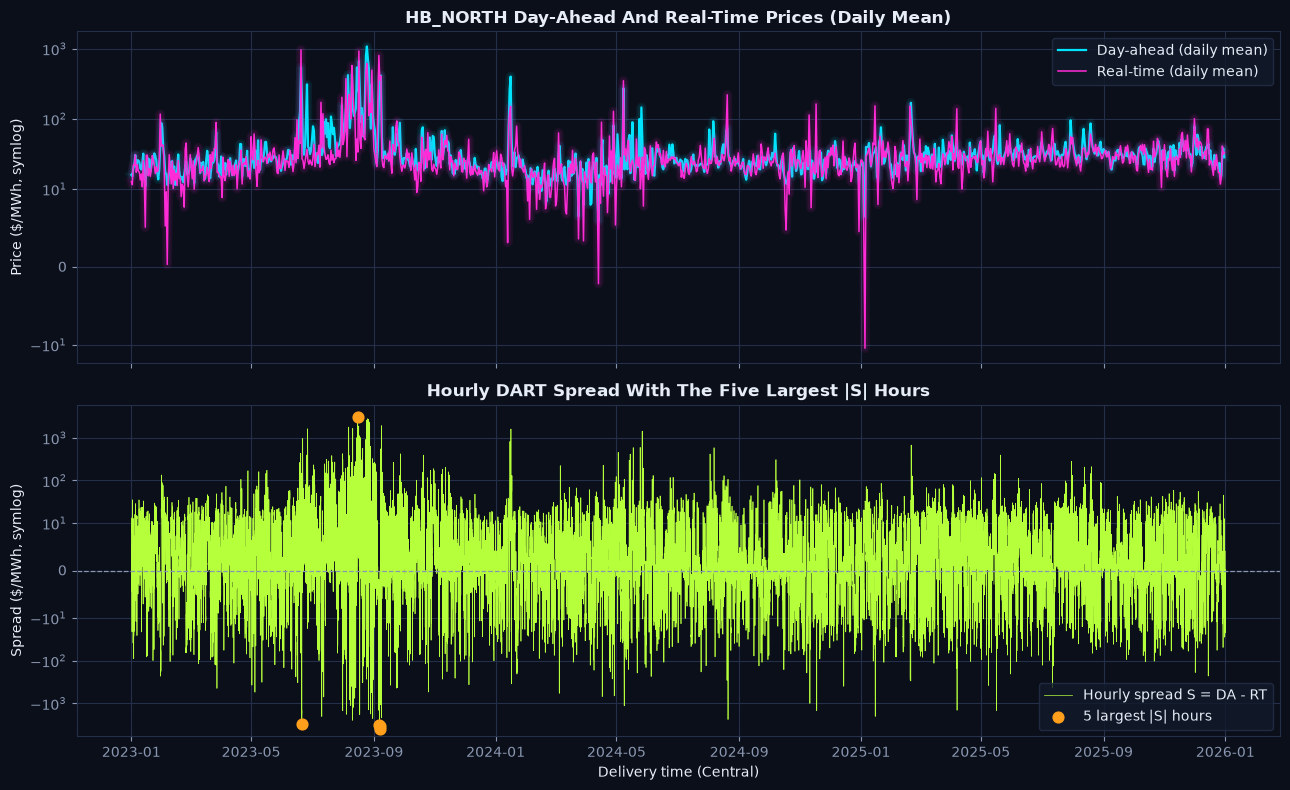

6.2 Five largest |S| hours:
interval_start_local  hour_ending  da_price  rt_price   spread  hours_that_day_with_abs_S_over_100
2023-09-06 19:00 CDT           20   1306.35   5229.84 -3923.49                                   8
2023-09-06 16:00 CDT           17    467.10   3893.24 -3426.14                                   8
2023-09-06 15:00 CDT           16    311.35   3536.42 -3225.06                                   8
2023-06-20 19:00 CDT           20   1964.91   5070.93 -3106.02                                   6
2023-08-15 19:00 CDT           20   3310.39    322.49  2987.90                                   8 

6.3 Negative prices (kept in the data, never removed):
      negative_da_hours  negative_rt_hours  lowest_da  lowest_rt
year                                                            
2023                  0                125        1.1     -31.63
2024                  6                189       -4.0     -31.78
2025                  0                224        0.0     -32

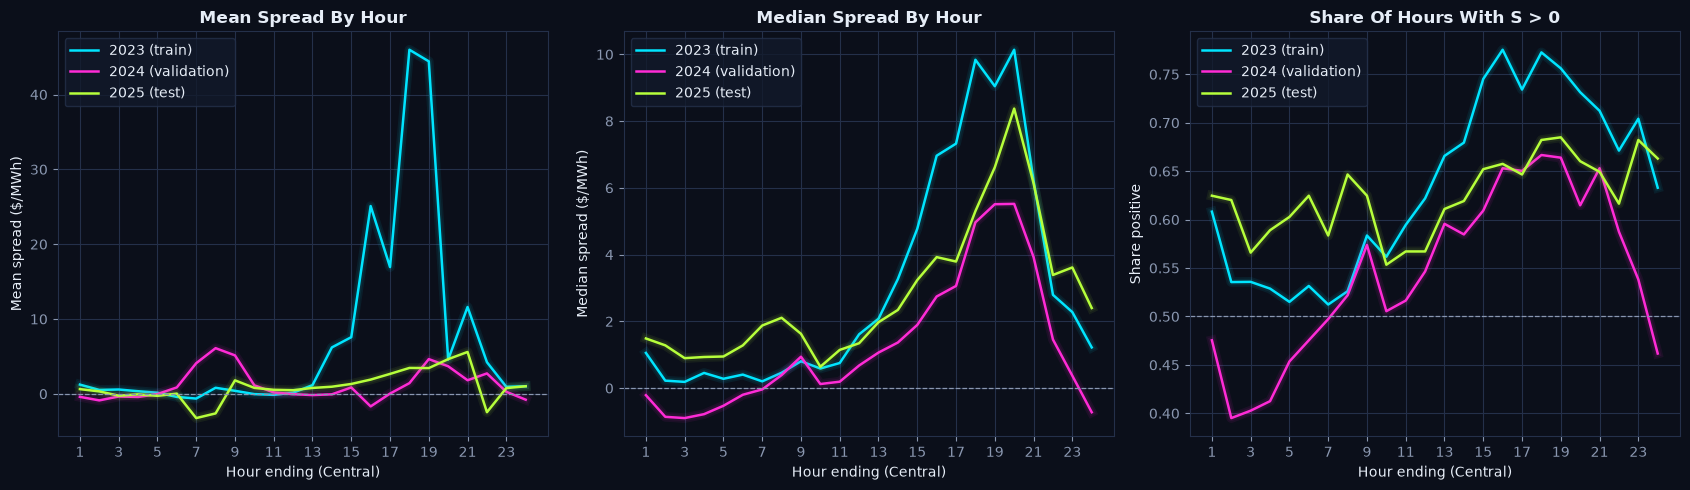

6.4 Hours (of 24) where S > 0 on most days: {2023: 24, 2024: 16, 2025: 24}
    Mean spread by year: {2023: 7.2, 2024: 1.17, 2025: 0.93}
Task 6 OK


In [18]:
# So, one neon look for the three figures of this cell (dark surface, glowing lines, every axis labelled).
plt.rcParams.update({"figure.facecolor": "#0B0F1A", "axes.facecolor": "#0B0F1A", "axes.edgecolor": "#24304A",
                     "axes.labelcolor": "#E6EDF7", "axes.titlecolor": "#E6EDF7", "xtick.color": "#8A97B0",
                     "ytick.color": "#8A97B0", "grid.color": "#24304A", "axes.grid": True, "text.color": "#E6EDF7",
                     "legend.facecolor": "#121a2b", "legend.edgecolor": "#24304A", "axes.titleweight": "bold",
                     "text.parse_math": True})
NEON_COLORS = ["#00E5FF", "#FF2BD6", "#B6FF3B", "#FF9F1C"]

def glow_plot(axis, x_values, y_values, color, label, width=1.6):
    # Let's do now the glow: the same line wider and fainter underneath, then the crisp line on top.
    for glow_width in (7, 4.5):
        axis.plot(x_values, y_values, color=color, linewidth=glow_width, alpha=0.07)
    axis.plot(x_values, y_values, color=color, linewidth=width, label=label)

model_years = df[df["delivery_date"].dt.year.isin([2023, 2024, 2025])].copy()
model_years["year"] = model_years["delivery_date"].dt.year

# ---- 6.1 Class balance per year = accuracy of Always INC
class_balance = model_years.groupby("year").agg(hours=("y", "size"), share_positive=("y", "mean"),
                                                mean_spread=("spread", "mean"), median_spread=("spread", "median"))
class_balance["always_inc_accuracy"] = class_balance["share_positive"]
print("6.1 Class balance (share positive = accuracy of Always INC):")
print(class_balance.round(4), "\n")

# ---- 6.2 DA, RT and spread over time + the five largest |S| hours
daily_prices = model_years.groupby("delivery_date")[["da_price", "rt_price"]].mean()
largest_five = model_years.loc[model_years["spread"].abs().nlargest(5).index]
neon_figure, (price_axis, spread_axis) = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
glow_plot(price_axis, daily_prices.index, daily_prices["da_price"], NEON_COLORS[0], "Day-ahead (daily mean)")
glow_plot(price_axis, daily_prices.index, daily_prices["rt_price"], NEON_COLORS[1], "Real-time (daily mean)", 1.1)
price_axis.set_yscale("symlog", linthresh=10)
price_axis.set_title("HB_NORTH Day-Ahead And Real-Time Prices (Daily Mean)")
price_axis.set_ylabel("Price ($/MWh, symlog)")
price_axis.legend(loc="upper right")
local_naive_time = model_years["interval_start_local"].dt.tz_localize(None)
spread_axis.plot(local_naive_time, model_years["spread"], color=NEON_COLORS[2], linewidth=0.5, label="Hourly spread S = DA - RT")
spread_axis.scatter(largest_five["interval_start_local"].dt.tz_localize(None), largest_five["spread"], s=60,
                    color=NEON_COLORS[3], zorder=4, label="5 largest |S| hours")
spread_axis.axhline(0, color="#8A97B0", linestyle="--", linewidth=0.9)
spread_axis.set_yscale("symlog", linthresh=10)
spread_axis.set_ylim(-6000, 6000)
spread_axis.set_title("Hourly DART Spread With The Five Largest |S| Hours")
spread_axis.set_xlabel("Delivery time (Central)")
spread_axis.set_ylabel("Spread ($/MWh, symlog)")
spread_axis.legend(loc="lower right")
neon_figure.tight_layout()
plt.show()
# So, error or real event? A data error is an isolated hour; a real event is a cluster of big spreads that day.
big_hours_per_day = model_years.assign(is_big=model_years["spread"].abs() > 100).groupby("delivery_date")["is_big"].sum()
extreme_table = largest_five[["interval_start_local", "hour_ending", "da_price", "rt_price", "spread"]].copy()
extreme_table["interval_start_local"] = extreme_table["interval_start_local"].dt.strftime("%Y-%m-%d %H:%M %Z")
extreme_table["hours_that_day_with_abs_S_over_100"] = largest_five["delivery_date"].map(big_hours_per_day).astype(int).values
print("6.2 Five largest |S| hours:")
print(extreme_table.round(2).to_string(index=False), "\n")

# ---- 6.3 Negative prices
negative_table = model_years.groupby("year").agg(negative_da_hours=("da_price", lambda s: int((s < 0).sum())),
                                                  negative_rt_hours=("rt_price", lambda s: int((s < 0).sum())),
                                                  lowest_da=("da_price", "min"), lowest_rt=("rt_price", "min"))
print("6.3 Negative prices (kept in the data, never removed):")
print(negative_table.round(2), "\n")

# ---- 6.4 Average spread and share positive by hour of day
hour_profile = model_years.groupby(["year", "hour_ending"]).agg(mean_spread=("spread", "mean"),
                                                                median_spread=("spread", "median"),
                                                                share_positive=("y", "mean")).reset_index()
neon_figure, (mean_axis, median_axis, share_axis) = plt.subplots(1, 3, figsize=(17, 5))
for color_position, each_year in enumerate([2023, 2024, 2025]):
    year_rows = hour_profile[hour_profile["year"] == each_year]
    label_text = {2023: "2023 (train)", 2024: "2024 (validation)", 2025: "2025 (test)"}[each_year]
    glow_plot(mean_axis, year_rows["hour_ending"], year_rows["mean_spread"], NEON_COLORS[color_position], label_text, 1.8)
    glow_plot(median_axis, year_rows["hour_ending"], year_rows["median_spread"], NEON_COLORS[color_position], label_text, 1.8)
    glow_plot(share_axis, year_rows["hour_ending"], year_rows["share_positive"], NEON_COLORS[color_position], label_text, 1.8)
for each_axis, title_text, y_text, reference in ((mean_axis, "Mean Spread By Hour", "Mean spread ($/MWh)", 0),
                                                 (median_axis, "Median Spread By Hour", "Median spread ($/MWh)", 0),
                                                 (share_axis, "Share Of Hours With S > 0", "Share positive", 0.5)):
    each_axis.axhline(reference, color="#8A97B0", linestyle="--", linewidth=0.9)
    each_axis.set_xticks(range(1, 25, 2))
    each_axis.set_title(title_text)
    each_axis.set_xlabel("Hour ending (Central)")
    each_axis.set_ylabel(y_text)
    each_axis.legend(loc="upper left")
neon_figure.tight_layout()
plt.show()
share_by_hour = hour_profile.pivot(index="year", columns="hour_ending", values="share_positive")
print("6.4 Hours (of 24) where S > 0 on most days:", (share_by_hour > 0.5).sum(axis=1).to_dict())
print("    Mean spread by year:", class_balance["mean_spread"].round(2).to_dict())
print("Task 6 OK")

**Answer (Task 6).**
1. Share of S > 0 (= accuracy of Always INC): 2023 63.5%, 2024 54.4%, 2025 62.5%.
2. The five largest |S| hours are 2023-09-06 HE16, HE17 and HE20 (S down to −$3,923), 2023-06-20 HE20 and 2023-08-15 HE20. They are real events, not data errors: each sits in a day with 6–8 hours of |S| > $100, during the summer 2023 scarcity, when RT (or DA) prices spiked for several hours.
3. Negative prices: DA 0 / 6 / 0 hours and RT 125 / 189 / 224 hours in 2023 / 2024 / 2025, mostly midday (solar) and overnight (wind). They are real market outcomes, so they stay in the data; robustness is handled in the models.
4. Yes, a modest one. The mean spread is positive every year ($7.20, $1.17, $0.93), S > 0 in most days in all 24 hours in 2023 and 2025 and in 16 of 24 hours in 2024. The premium is concentrated in the afternoon and evening peak (HE15–HE21, median spread about $4–10); in 2024 the overnight hours lean negative.

## What to keep for Project 2

* Your functions (notebook or `.py` module): Project 2 must regenerate every result from the raw files.
* `ercot_hb_north_hourly.csv`. `da_price`, `rt_price`, `spread` and `y` of day $D$ are **outcomes**: labels and P&L only.
  Price features must come from $D-2$ or earlier, and every feature you build should pass `assert_no_lookahead`.